# Titanic Survival Prediction with SHAP Explanations

In [56]:
import textwrap
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier
import shap
import matplotlib.pyplot as plt
import ollama

## The Data

We're using the classic **Titanic passenger dataset** (via `seaborn`), which records each passenger's characteristics with the "target" of our model being whether they survived the sinking. This is an academic example, but the same process applies directly to binary classification models built on similarly-shaped tabular data in industry such as fraud detection, credit scoring, or churn prediction. 

It's a dataset where we already have a rough intuition for *why* someone survived, which makes it easy to check whether SHAP's explanations and the LLM narration built on top of them actually match reality. Some generally known predictors of survival:


Sex - "women and children first" was enforced at the lifeboats, especially early on. Women survived at far higher rates than men.

Passenger class (pclass) -  first-class cabins and public rooms were closer to the boat deck, and class also correlated with priority/awareness getting to boats.

Fare - closely tracks class, so it's largely the same signal (higher fare = better odds).

Age - children were prioritized under the same evacuation norm.

Family size (sibsp/parch) - non-monotonic: traveling completely alone or in a very large family group both hurt odds (alone = no one to help you find a boat; large family = harder to keep everyone together before boats left), while a small family (e.g. a spouse or 1-2 kids) helped somewhat.

Port of embarkation (embarked) - a weaker signal. It correlates with class/fare (Cherbourg passengers skewed wealthier) rather than causing survival directly.

In [57]:
# Load and prep Titanic data
df = sns.load_dataset("titanic")

features = ["pclass", "age", "sibsp", "parch", "fare", "sex", "embarked"]
df = df[features + ["survived"]].dropna()

# Encode categoricals
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df["embarked"] = df["embarked"].map({"S": 0, "C": 1, "Q": 2})

X = df[features]
y = df["survived"]

print(f"Dataset shape: {X.shape}")
display(X.head())

print("\nTarget (y) - 'survived':")
display(y.head())
print(y.value_counts())

Dataset shape: (712, 7)


,pclass,age,sibsp,parch,fare,sex,embarked
0,3,22.0,1,0,7.2500,0,0
1,1,38.0,1,0,71.2833,1,1
2,3,26.0,0,0,7.9250,1,0
3,1,35.0,1,0,53.1000,1,0
4,3,35.0,0,0,8.0500,0,0



Target (y) - 'survived':


0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64

survived
0    424
1    288
Name: count, dtype: int64


## Train Gradient Boosting Model

We're training a **gradient boosting classifier**, a tree-based model. It's a good model to explain with SHAP for the same reason it's popular in industry: it captures non-linear relationships and feature interactions that a plain logistic regression would miss, but that expressiveness comes at the cost of being a **black box**.

Normally, before trusting a model's predictions enough to explain them, you'd want to evaluate it properly, such as using a hold out set to evaluate performance metrics. We're going to keep this step simple and focus on explaining the model.

In [58]:
gb_model = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gb_model.fit(X, y)

train_acc = gb_model.score(X, y)
print(f"Training accuracy: {train_acc:.3f}")

Training accuracy: 0.910


## SHAP Explanations

### What is TreeExplainer?

`shap.TreeExplainer` is a SHAP explainer specialized for tree-based models (gradient boosting, random forests, XGBoost, LightGBM, CatBoost). Instead of *approximating* Shapley values by sampling, it computes them exactly by exploiting the fact that a decision tree's structure already tells you exactly which features were used and in what order along every path.

### The model-agnostic alternative: KernelSHAP

The general-purpose version is `shap.KernelExplainer` ("KernelSHAP"). It treats the model as a pure black box. It only needs a `predict` function and estimates Shapley values by sampling many random feature coalitions. It works on *any* model (neural nets, SVMs, arbitrary pipelines), but it's slow and only approximate, because it's sampling its way toward an answer instead of computing one directly. 

### Why TreeExplainer here

Our model is a `GradientBoostingClassifier`, a tree-based model, so we don't need to fall back to sampling. It's both much faster and much simpler to deploy than the model-agnostic alternative of KernalSHAP.


In [59]:
# To generate the explainer object we just need the trained model object.
explainer = shap.TreeExplainer(gb_model)
shap_values = explainer(X)

# shap_values has shape (n_samples, n_features) - index [1] selects the "survived" class
print(f"SHAP values shape: {shap_values.values.shape}")

SHAP values shape: (712, 7)


### A Useful Mental Model: SHAP Values as "Coefficients"

It's worth stepping back and noticing that SHAP's output looks a lot like something more familiar: the coefficients of a **logistic regression** model (or a plain linear regression, if our target were continuous instead of binary).

The key difference is that a logistic regression's coefficients are **fixed** at one number per feature, for every instance. SHAP values are **per-instance** where a feature can have a different SHAP value for every passenger.

In [60]:
# Look at the raw SHAP values for a single passenger
idx = 0

print("Feature names:      ", shap_values.feature_names)
print("Raw feature values: ", shap_values.data[idx])
print("SHAP values:        ", shap_values.values[idx])
print("Base value (intercept, i.e. E[f(X)]):", shap_values.base_values[idx])

# Additivity check: base value + sum of SHAP values == the model's raw output
reconstructed = shap_values.base_values[idx] + shap_values.values[idx].sum()
actual_margin = gb_model.decision_function(X.iloc[[idx]])[0]
print(f"\nBase + sum(SHAP values) = {reconstructed:.6f}")
print(f"Model's actual raw output (log-odds) = {actual_margin:.6f}")

# TreeExplainer's values are on the log-odds (margin) scale, not probability 
# apply the sigmoid to convert to the predicted probability of survival.
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

print(f"\nPredicted probability of survival = {sigmoid(reconstructed):.4f}")

Feature names:       ['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex', 'embarked']
Raw feature values:  [ 3.   22.    1.    0.    7.25  0.    0.  ]
SHAP values:         [-0.5091732  -0.21327523  0.01826223  0.00742133  0.08824832 -1.19139376
 -0.11621874]
Base value (intercept, i.e. E[f(X)]): -0.4614131697722688

Base + sum(SHAP values) = -2.377542
Model's actual raw output (log-odds) = -2.377542

Predicted probability of survival = 0.0849


### Global Feature Importance - Bar Plot
Each bar shows the **mean absolute SHAP value** for one feature across all 712 passengers, a measure of how much that feature moved predictions on average, regardless of direction.

- Longer bar = stronger average influence on survival predictions.
- This is a global summary: it collapses across all passengers, so it won't tell you *how* a feature affects predictions (up or down), only *how much* it matters overall.
- `sex` and `pclass` dominating here means those two features are doing the most work in the model, in line with the well-known "women and children (first class) first" rescue priority.

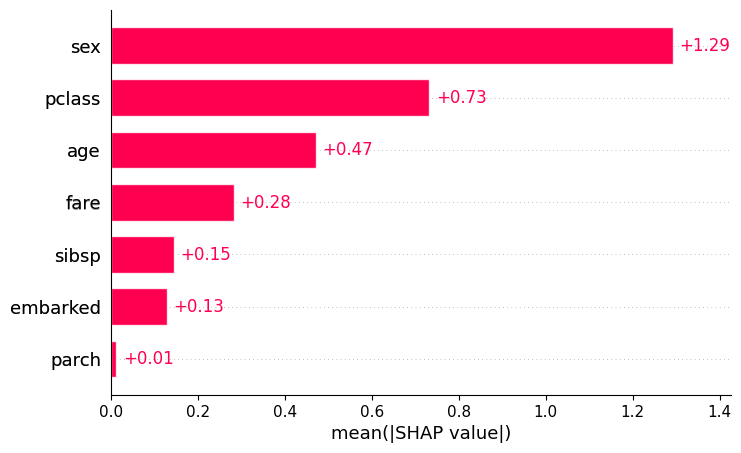

In [61]:
shap.plots.bar(shap_values)

### Beeswarm Plot
The beeswarm is the richest single-panel SHAP summary - it shows **every passenger × every feature** at once.

- **Each dot** is one passenger for one feature.
- **X-axis position** = the SHAP value: how much that feature pushed the model's output toward "survived" (positive) or "did not survive" (negative).
- **Dot color** = the actual feature value for that passenger - red means the feature value was high, blue means low.
- **Vertical spread** within a row is just to prevent dots from overlapping; it carries no meaning.

Reading patterns:
- A row that is mostly red on the right and blue on the left means *high values of that feature help survival* (e.g. `fare` - expensive tickets → better odds).
- A row that is mostly blue on the right and red on the left means *low values help survival* (e.g. `pclass` - lower number = first class → better odds).
- A tight cluster near 0 means the feature rarely changes the prediction much (e.g. `parch`).

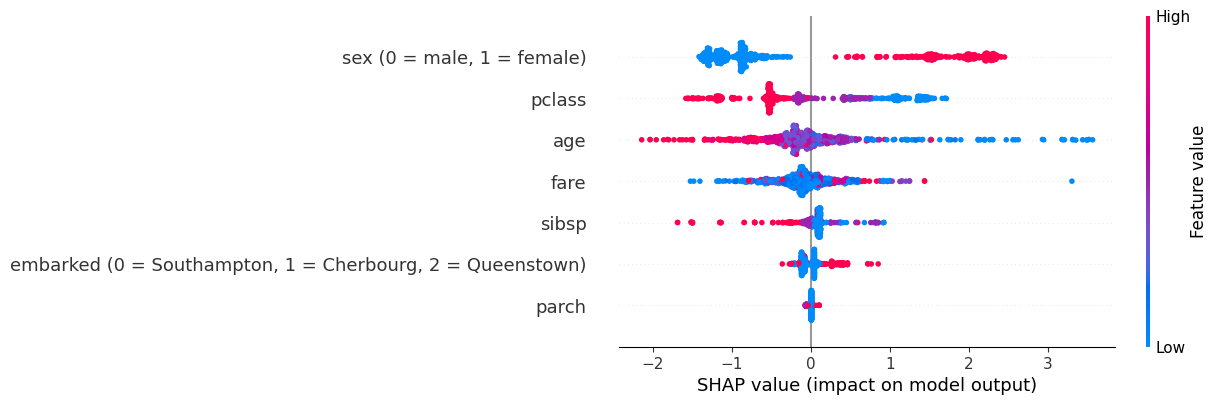

In [62]:
# Rebuild the feature names to spell out what each categorical code means
feature_names_mapped = [
    "sex (0 = male, 1 = female)" if name == "sex"
    else "embarked (0 = Southampton, 1 = Cherbourg, 2 = Queenstown)" if name == "embarked"
    else name
    for name in shap_values.feature_names
]

shap_values_labeled = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=shap_values.data,
    feature_names=feature_names_mapped,
)

shap.plots.beeswarm(shap_values_labeled)

### Waterfall Plot - Single Passenger Explanation
The waterfall plot shows exactly **how the model arrived at one prediction**, feature by feature.

- It starts at `E[f(X)]` - the model's average prediction across all passengers (the baseline).
- Each bar then shows how one feature **pushed the probability up** (red, positive) or **down** (blue, negative) from that baseline.
- The final value `f(x)` at the top is the model's actual predicted probability for this passenger.
- Feature values for this specific passenger are shown on the left (e.g. `sex = female`).

In [63]:
VALUE_LABELS = {
    "sex": {0: "male", 1: "female"},
    "embarked": {0: "Southampton", 1: "Cherbourg", 2: "Queenstown"},
}


def decode_value(feature, val):
    mapping = VALUE_LABELS.get(feature)
    if mapping is None:
        return val
    return mapping.get(val, val)


def plot_waterfall(idx):
    """Display SHAP waterfall plot with actual/predicted outcome in the title."""
    sv = shap_values[idx]
    survival_prob = gb_model.predict_proba(X.iloc[[idx]])[0][1]
    predicted = "survived" if survival_prob >= 0.5 else "did not survive"
    actual = "survived" if y.iloc[idx] else "did not survive"

    sv_disp = shap.Explanation(
        values=sv.values,
        base_values=sv.base_values,
        data=sv.data,
        display_data=np.array([decode_value(name, val) for name, val in zip(sv.feature_names, sv.data)]),
        feature_names=sv.feature_names,
    )
    shap.plots.waterfall(sv_disp, show=False)
    plt.title(
        f"Passenger {idx}  |  Actual: {actual}  |  Predicted: {predicted} ({survival_prob:.1%})",
        fontsize=10,
    )
    plt.tight_layout()
    plt.show()

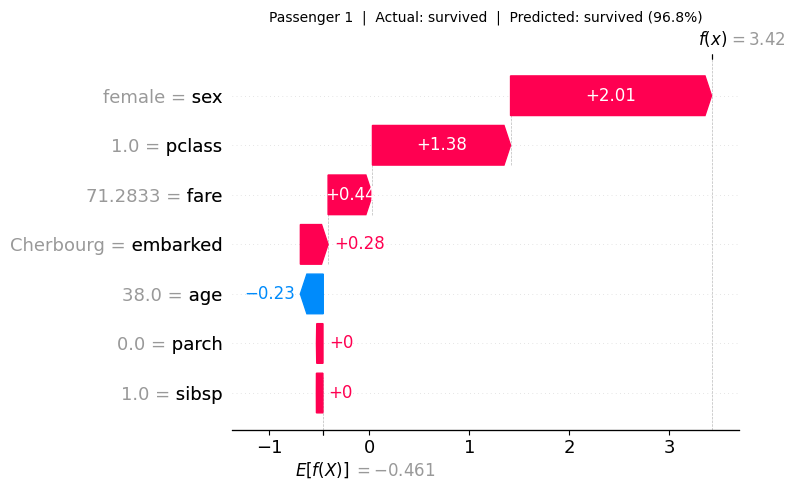

In [64]:
passenger_idx = 1
plot_waterfall(passenger_idx)

### More Plots to Explore

SHAP supports many more plot types beyond what's shown here. See the [SHAP GitHub repo](https://github.com/shap/shap) for the full gallery.

## AI Explanation of the Waterfall Plot via Ollama

### Why Add AI-Assisted Explanation?

The waterfall plot above is precise, but reading it requires some technical background. Most people who'd actually want an explanation for a decision (a loan applicant, a claims reviewer, a non-technical stakeholder) aren't going to interpret a waterfall plot. This is the interpretability vs. explainability gap: SHAP gives us an accurate, interpretable account of *why* the model predicted what it did, but not yet a plain-language justification anyone can follow.

That's what the next step adds. The LLM isn't doing any of the actual explanatory work, it's just translating a technical artifact into a sentence a non-technical reader can understand.

In [65]:
MODEL = "llama3.1"


def explain_passenger(idx):
    """Stream a plain-English SHAP explanation for passenger at row idx."""
    sv = shap_values[idx]
    survival_prob = gb_model.predict_proba(X.iloc[[idx]])[0][1]
    predicted = "survived" if survival_prob >= 0.5 else "did not survive"
    actual = "survived" if y.iloc[idx] else "did not survive"

    shap_lines = "\n".join(
        f"  {name:12s}  value={decode_value(name, val):<8}  shap={contrib:+.4f}"
        for name, val, contrib in sorted(
            zip(sv.feature_names, sv.data, sv.values),
            key=lambda t: abs(t[2]),
            reverse=True,
        )
    )

    prompt = f"""
    You are explaining a prediction to someone with no technical background. Use no unnecessary language and use plain everyday language - no jargon.

    Passenger: {dict(X.iloc[idx])}
    Actual outcome: {actual}
    Predicted outcome: {predicted} ({survival_prob:.1%} probability)

    Feature contributions (positive = pushed toward survived, negative = pushed toward did not survive):
    {shap_lines}

    In 2-3 sentences, explain who this passenger was, what was predicted to happen and what did. Also explain which characteristics contributed most to surviving or not
    """

    response = ollama.chat(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        keep_alive="10m",
    ).message.content
    print(textwrap.fill(response, width=80))


def explain_with_plot(idx):
    """Show the waterfall plot then stream the LLM explanation for passenger at row idx."""
    plot_waterfall(idx)
    explain_passenger(idx)

In [66]:
passenger_idx = 1
explain_passenger(passenger_idx)

This passenger was a 38-year-old woman who was traveling in first class (pclass)
and paid a relatively high fare. The model predicted she had a 96.8% chance of
surviving, which turned out to be correct. The characteristics that contributed
most to her survival were being a woman, traveling in first class, and paying a
high fare - all positive contributors.


## Batch Examples - 5 Passengers

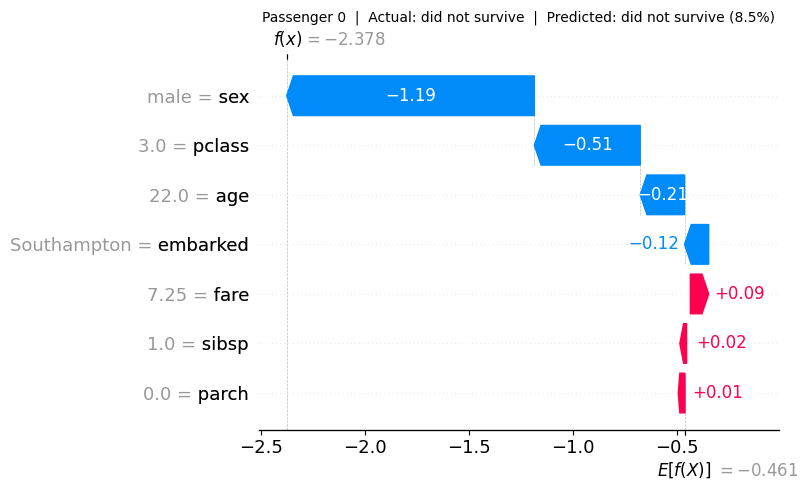

This passenger was a 22-year-old man who was traveling in third class on the
ship. The model predicted that he had an 8.5% chance of surviving the disaster,
and unfortunately, that's what actually happened. The characteristics that
contributed to his likelihood of not surviving were being a man (negative
contribution), traveling in third class (negative contribution), and being young
(negative contribution).




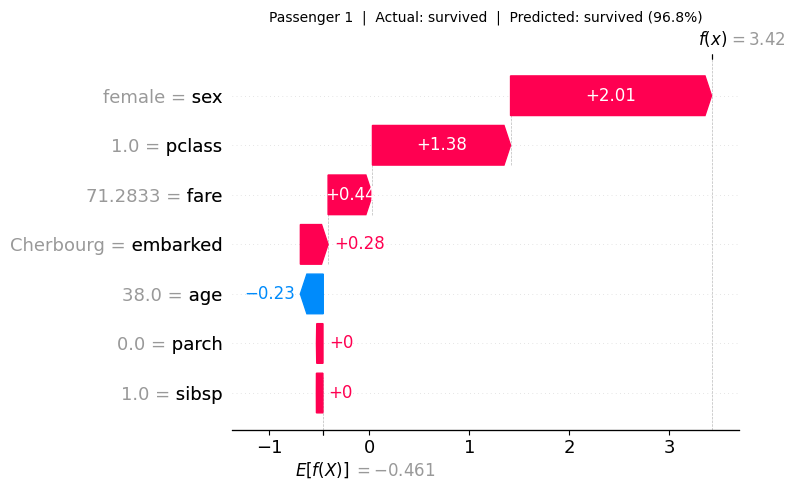

This passenger was a 38-year-old woman who traveled in first class (pclass=1.0),
paid a high fare, and was traveling from Cherbourg. The model predicted that she
had a 96.8% chance of surviving the ship's sinking, and that's exactly what
happened. The characteristics that most contributed to her survival were being a
woman (pushed her toward surviving) and traveling in first class, while her age
actually slightly decreased her chances of survival.




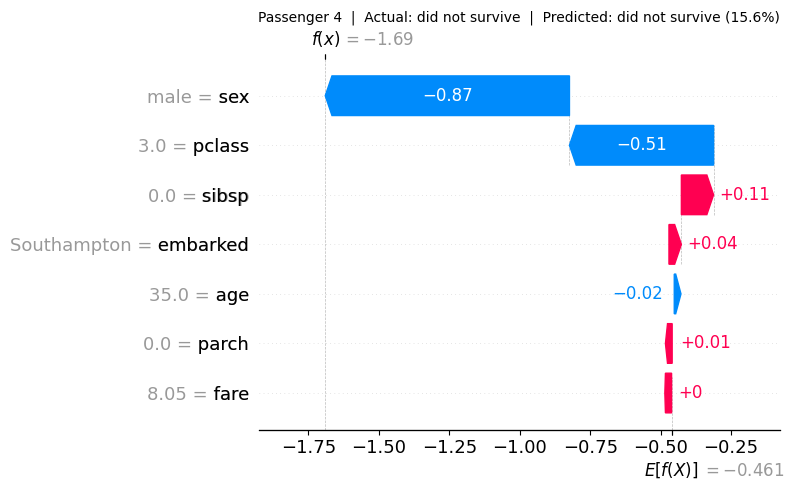

This passenger was a 35-year-old man who traveled in third class on a ship that
departed from Southampton. The model predicted that he would not survive with a
15.6% probability, and that's exactly what happened. The characteristics that
most contributed to him not surviving were being a male (male passengers had a
higher chance of not surviving), being in third class, and being 35 years old.




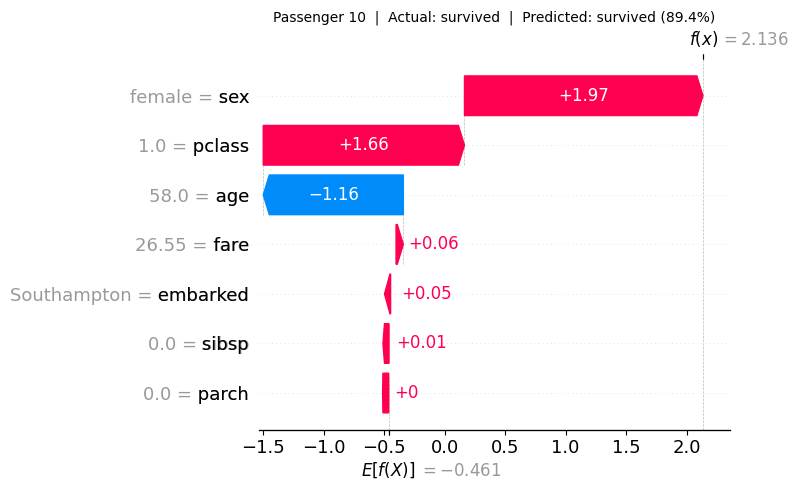

This passenger was a 58-year-old female who paid a fare of $26.55 to travel
first class from Southampton. The model predicted that she had a 89.4% chance of
surviving the Titanic disaster, and that's exactly what happened. The model
thinks that being female and traveling first class (pclass) were the main
reasons she survived, but her age actually worked against her a bit.




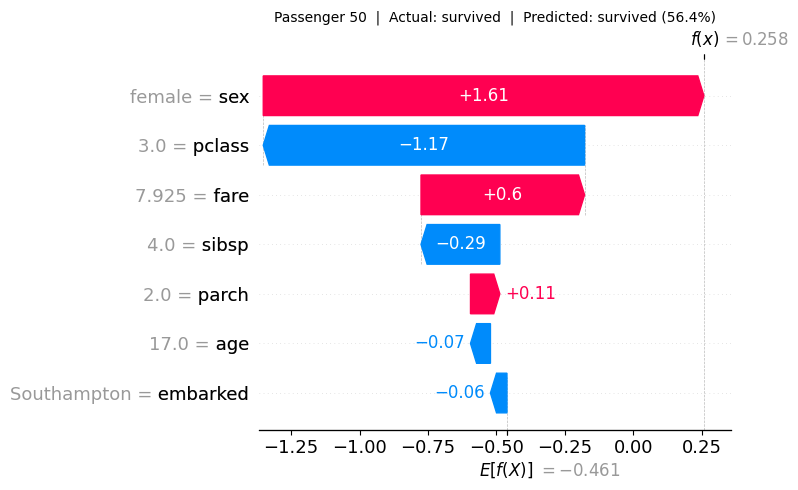

This passenger was a young woman (17 years old) who was traveling in third class
(not first or second class) and had a relatively low fare. We predicted that she
would survive with a 56.4% probability, and that's what actually happened. The
characteristics that contributed most to her survival were being a woman (which
helped a lot), having a relatively low fare, and traveling with some family (she
had a lot of siblings and parents on board).




In [67]:
for idx in [0, 1, 4, 10, 50]:
    explain_with_plot(idx)
    print("\n" + "=" * 60 + "\n")

# How Much Context Does the Narration Need?

Everything above handed the LLM the SHAP values, the feature values, and plain language labels all at once. Those are three separate things, so it is worth pulling them apart to see which one is doing the work.

The explanation gets rebuilt three times:

| Level | What the LLM is given |
| --- | --- |
| 1 | feature names and their SHAP contributions, and **nothing else** |
| 2 | the same, plus each feature's actual value |
| 3 | the same, plus a glossary of what the feature means and why that value mattered |

The SHAP values are identical at every level. Only the surrounding context changes.

## The Glossary for Level 3

Levels 1 and 2 are free: level 1 is what SHAP already gives you, and level 2 needs only the `VALUE_LABELS` mapping used to encode the data.

Level 3 is hand written. In a real deployment this is the feature dictionary that lives alongside the model.

In [1]:
FEATURE_CONTEXT = {
    "pclass": {
        "description": "Ticket class. Stands in for wealth and for physical location on the ship.",
        "values": {
            1: "First class. Cabins on the upper decks, nearest the boat deck where lifeboats launched.",
            2: "Second class. Mid ship and mid deck, a moderate distance from the lifeboats.",
            3: "Third class. Lower decks, the longest route to the boat deck, with gates and stairways between sections.",
        },
    },
    "sex": {
        "description": (
            "Recorded sex. The evacuation followed 'women and children first', enforced far "
            "more strictly in first and second class than in third."
        ),
        "values": {
            0: "Male. Men were loaded only after women and children, and many were turned away.",
            1: "Female. Prioritised at the lifeboats, which is why this is the strongest factor in the model.",
        },
    },
    "age": {
        "description": "Age in years. Children were prioritised alongside women.",
        "bands": [
            (12, "A child, and so prioritised at the lifeboats alongside women."),
            (18, "An adolescent, treated as an adult by some crews and as a child by others."),
            (50, "A working age adult, with no evacuation priority beyond what sex and class conferred."),
            (200, "An older adult, who faced the added difficulty of reaching the boat deck quickly."),
        ],
    },
    "sibsp": {
        "description": (
            "Count of siblings and spouses aboard. This counts family only, so a passenger "
            "travelling with a servant or a colleague is recorded as 0, the same as someone "
            "travelling completely alone."
        ),
        "bands": [
            (1, "No siblings or spouse aboard, though possibly travelling with companions this feature cannot see."),
            (2, "One sibling or a spouse aboard, the group size with the best survival odds."),
            (20, "Several siblings aboard, usually a large family that struggled to stay together."),
        ],
    },
    "parch": {
        "description": "Count of parents and children aboard. Same family-only blind spot as sibsp.",
        "bands": [
            (1, "No parents or children aboard."),
            (3, "Travelling with a small number of parents or children."),
            (20, "Travelling with a large number of parents or children."),
        ],
    },
    "fare": {
        "description": (
            "Ticket price in 1912 pounds. Tracks class closely, so it is partly a second "
            "reading of the signal already in pclass."
        ),
        "bands": [
            (10, "A cheap third class fare."),
            (30, "A typical third or low second class fare."),
            (80, "A comfortable second or lower first class fare."),
            (10000, "An expensive first class fare, implying a well placed cabin on an upper deck."),
        ],
    },
    "embarked": {
        "description": (
            "Port where the passenger boarded. The port did not save anyone. It correlates "
            "with class and nationality, so the model picks it up as a weak proxy for those."
        ),
        "values": {
            0: "Southampton, the main departure port. Most of the passengers, and only 19 percent of them first class.",
            1: "Cherbourg, France. Skewed wealthy at 57 percent first class, including American millionaires returning home.",
            2: "Queenstown, Ireland, the final stop. Almost entirely third class, and only 28 of the modelled passengers.",
        },
    },
}

## Rendering the Same SHAP Values Three Ways

`shap_block` is the only thing that differs between the levels.

In [2]:
def show(feature, value):
    """decode_value, but without the trailing .0 on whole numbers like pclass."""
    decoded = decode_value(feature, value)
    if isinstance(decoded, float) and decoded.is_integer():
        return int(decoded)
    return decoded


def describe_value(feature, value):
    """The glossary sentence for one specific value of one feature."""
    entry = FEATURE_CONTEXT[feature]
    if "values" in entry:
        return entry["values"].get(int(value), "")
    for upper, text in entry["bands"]:
        if value < upper:
            return text
    return ""


def shap_block(idx, level, top_n=4):
    """Render one passenger's SHAP values at the given context level."""
    sv = shap_values[idx]
    ranked = sorted(
        zip(sv.feature_names, sv.data, sv.values),
        key=lambda t: abs(t[2]),
        reverse=True,
    )

    if level == 1:
        # Contributions only. Nothing about what the values actually were.
        return "\n".join(
            f"  {name:12s} contribution={contrib:+.4f}" for name, _, contrib in ranked
        )

    if level == 2:
        return "\n".join(
            f"  {name:12s} value={show(name, value)!s:<12} contribution={contrib:+.4f}"
            for name, value, contrib in ranked
        )

    lines = []
    for name, value, contrib in ranked[:top_n]:
        lines.append(f"  {name} = {show(name, value)} (contribution {contrib:+.3f})")
        for label, text in (
            ("What it is", FEATURE_CONTEXT[name]["description"]),
            ("This value", describe_value(name, value)),
        ):
            # Wrap so the cell output has a predictable height instead of relying on
            # whatever width the notebook happens to render at.
            lines.append(
                textwrap.fill(
                    f"{label}: {text}",
                    width=78,
                    initial_indent="    ",
                    subsequent_indent="      ",
                )
            )
    return "\n".join(lines)

In [3]:
LEVEL_NAMES = {1: "CONTRIBUTIONS ONLY", 2: "PLUS THE VALUES", 3: "PLUS THE GLOSSARY"}


def narrate(idx, level):
    """Explain one passenger at one context level. Everything else held constant."""
    survival_prob = gb_model.predict_proba(X.iloc[[idx]])[0][1]
    predicted = "survived" if survival_prob >= 0.5 else "did not survive"
    actual = "survived" if y.iloc[idx] else "did not survive"

    prompt = f"""
    You are explaining a model prediction to someone with no technical background.
    Use plain everyday language, no jargon.

    Predicted: {predicted} ({survival_prob:.1%} chance of survival)
    What actually happened: {actual}

    Factors that moved this prediction most. Positive pushed toward survival.
{shap_block(idx, level)}

    Write one paragraph of 4 to 6 sentences, no headings or bullet points, explaining the
    prediction and the largest factors behind it.
    """

    response = ollama.chat(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        options={"temperature": 0},
        keep_alive="10m",
    ).message.content
    return textwrap.fill(response.strip(), width=80)


from html import escape as _escape

from IPython.display import HTML


def show_level(idx, level, as_html=True):
    """Narrate one passenger at one level, showing the input alongside the output.

    Printing the input matters: the level 1 paragraph reads as though it knows the
    passenger's sex and class, so you need the input next to it to see that it does not.

    Rendered as one HTML block by default. Plain printed output gets truncated into a
    scrollable box once it passes the editor's line limit, which is 30 lines in VS Code,
    and the level 3 input alone is longer than that. Pass as_html=False for plain text.
    """
    text = "\n".join([
        f"LEVEL {level}: {LEVEL_NAMES[level]}  (passenger {idx})",
        "=" * 78,
        "WHAT THE LLM WAS GIVEN:",
        shap_block(idx, level),
        "",
        "WHAT IT WROTE:",
        narrate(idx, level),
    ])

    if not as_html:
        print(text)
        return

    display(HTML(
        "<pre style='white-space:pre-wrap;font-family:monospace;font-size:12.5px;"
        f"line-height:1.4;margin:0'>{_escape(text)}</pre>"
    ))

## Compare the Three Levels

Pick a passenger once, then run the next three cells one at a time. Passenger 1 is a first class woman from Cherbourg who survived.

In [4]:
context_idx = 1 

plot_waterfall(context_idx)

NameError: name 'plot_waterfall' is not defined

### Level 1: Contributions Only

The input is seven feature names and seven numbers. No sex, no class, no fare, no port.

Read the paragraph against the input directly above it, and look for any specific detail about this passenger that the input never contained.

In [ ]:
show_level(context_idx, 1)

Whatever specifics turned up, they did not come from the input. The signs are enough to work backwards from: `sex` is large and positive, and women survived the Titanic.

Note that nothing in the paragraph marks which claims are supported.

### Level 2: Plus the Values

Now it has the actual values.

In [ ]:
show_level(context_idx, 2)

Does it say *why* any of those factors mattered?

### Level 3: Plus the Glossary

Same numbers as level 1.

In [ ]:
show_level(context_idx, 3)

## What to Notice

Context bought two different things, worth keeping separate:

- **The values bought accuracy.** Level 1 to level 2 is where the narration stops filling gaps on its own.
- **The glossary bought explanation.** Level 2 to level 3 is where reasons appear, rather than restated magnitudes.